# Complete Machine Learning Model — Simple Example

**Goal:** Train a model to predict a flower species from measurements using the built-in Iris dataset.

This notebook follows the usual machine-learning workflow:
1. Import libraries
2. Load and explore data
3. Prepare features (`X`) and target (`y`)
4. Split data into training and testing sets
5. Train a model
6. Make predictions
7. Evaluate model performance
8. Test a new example
9. Save and reload the trained model

**Model:** K-Nearest Neighbors (KNN) classifier  
**Dataset:** Iris (included with scikit-learn; no download required)

> Run the cells from top to bottom. This is a classification example: the model predicts a flower category.

## 1. Install the required libraries
If these packages are not installed in your Python environment, run the next cell once.

In [1]:
%pip install pandas numpy matplotlib scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


## 3. Load the dataset

In [3]:
iris = load_iris(as_frame=True)

df = iris.frame
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


## 4. Explore the data

In [4]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe())

print("\nSpecies counts:")
print(df["target"].map(dict(enumerate(iris.target_names))).value_counts())

Dataset shape: (150, 5)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Missing values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Summary statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000



Species counts:
target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 5. Visualize the data

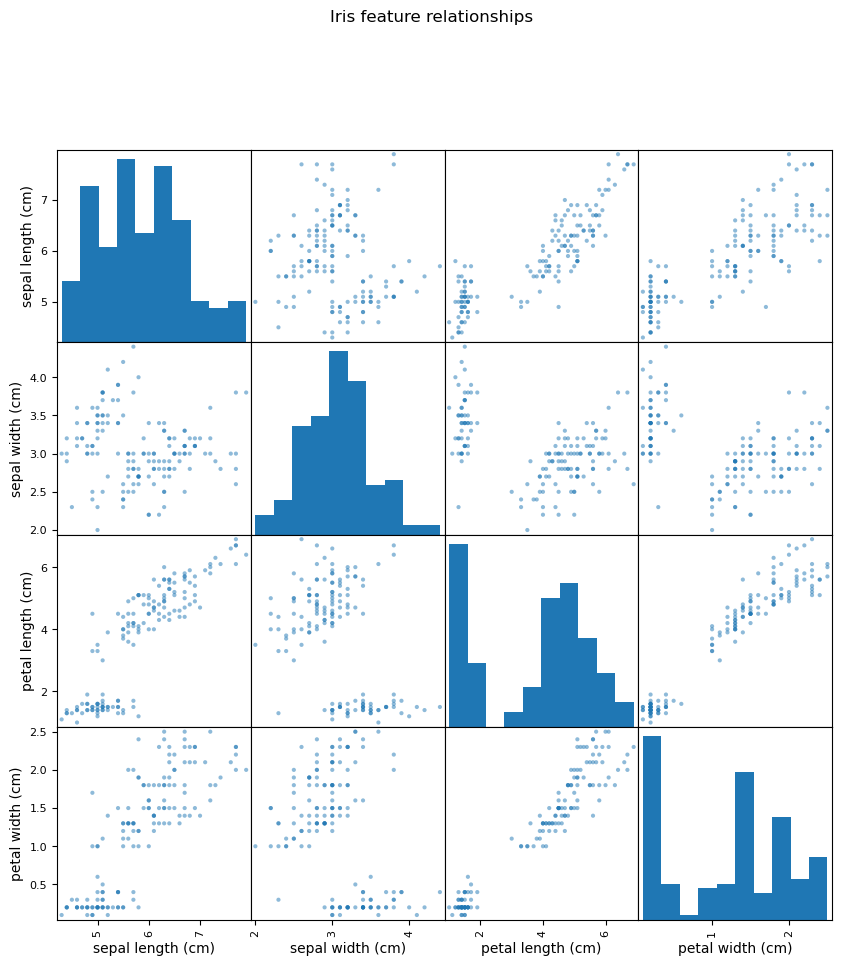

In [5]:
pd.plotting.scatter_matrix(
    df[["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]],
    figsize=(10, 10),
    diagonal="hist"
)
plt.suptitle("Iris feature relationships", y=1.02)
plt.show()

## 6. Separate features (`X`) and target (`y`)

- **Features (`X`)** are the measurements used to make a prediction.
- **Target (`y`)** is the flower category the model learns to predict.

In [6]:
X = df.drop(columns="target")
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeature examples:")
display(X.head())

print("\nTarget examples (numeric labels):")
print(y.head().tolist())
print("Target names:", iris.target_names)

X shape: (150, 4)
y shape: (150,)

Feature examples:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



Target examples (numeric labels):
[0, 0, 0, 0, 0]
Target names: ['setosa' 'versicolor' 'virginica']


## 7. Split into training and testing data
The model learns from the training set. The test set is held back to check how well it works on unseen examples.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))

Training examples: 120
Testing examples: 30


## 8. Build and train the model

A pipeline first standardizes the measurements, then trains a KNN classifier. Scaling matters because KNN compares distances between examples.

In [8]:
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

model.fit(X_train, y_train)
print("Model training complete!")

Model training complete!


## 9. Make predictions

In [9]:
y_pred = model.predict(X_test)

results = X_test.copy()
results["actual_species"] = [iris.target_names[i] for i in y_test]
results["predicted_species"] = [iris.target_names[i] for i in y_pred]

display(results.head(10))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),actual_species,predicted_species
38,4.4,3.0,1.3,0.2,setosa,setosa
127,6.1,3.0,4.9,1.8,virginica,virginica
57,4.9,2.4,3.3,1.0,versicolor,versicolor
93,5.0,2.3,3.3,1.0,versicolor,versicolor
42,4.4,3.2,1.3,0.2,setosa,setosa
56,6.3,3.3,4.7,1.6,versicolor,versicolor
22,4.6,3.6,1.0,0.2,setosa,setosa
20,5.4,3.4,1.7,0.2,setosa,setosa
147,6.5,3.0,5.2,2.0,virginica,virginica
84,5.4,3.0,4.5,1.5,versicolor,versicolor


## 10. Evaluate the model

In [10]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy:.2%}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Test accuracy: 93.33%

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



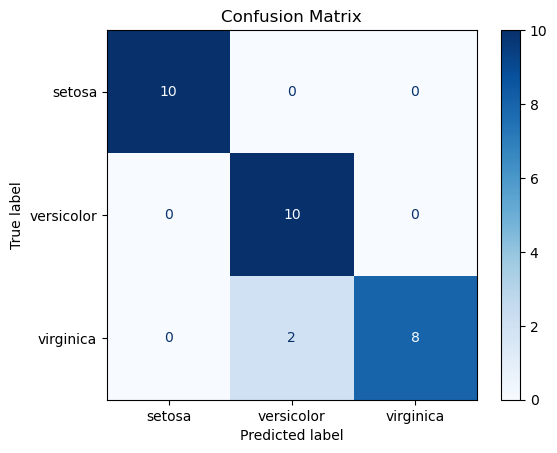

In [11]:
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

### How to read the results
- **Accuracy** is the fraction of test examples classified correctly.
- **Precision** tells you how often predictions for a species were correct.
- **Recall** tells you how many real examples of a species the model found.
- **F1-score** combines precision and recall.
- In a confusion matrix, the diagonal contains correct predictions; off-diagonal values are mistakes.

## 11. Predict a new flower
Enter four measurements in this order: sepal length, sepal width, petal length, petal width (all in centimeters).

In [12]:
new_flower = pd.DataFrame([{
    "sepal length (cm)": 5.1,
    "sepal width (cm)": 3.5,
    "petal length (cm)": 1.4,
    "petal width (cm)": 0.2
}])

prediction = model.predict(new_flower)[0]
probabilities = model.predict_proba(new_flower)[0]

print("Predicted species:", iris.target_names[prediction])
print("\nModel probability estimates:")
for species, probability in zip(iris.target_names, probabilities):
    print(f"{species}: {probability:.2%}")

Predicted species: setosa

Model probability estimates:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%


## 12. Save the trained model

This saves the complete pipeline, including the scaler and classifier. The Iris dataset is only needed here to show the target names; the saved model itself can make predictions without retraining.

In [13]:
model_path = "iris_knn_model.joblib"
joblib.dump(model, model_path)
print(f"Model saved to: {model_path}")

Model saved to: iris_knn_model.joblib


## 13. Load the model and use it again

In [14]:
loaded_model = joblib.load("iris_knn_model.joblib")
loaded_prediction = loaded_model.predict(new_flower)[0]

print("Prediction from loaded model:", iris.target_names[loaded_prediction])

Prediction from loaded model: setosa


## 14. Machine-learning workflow recap

1. **Load data** — obtain examples and labels.
2. **Explore data** — inspect columns, missing values, distributions, and patterns.
3. **Prepare data** — separate features from the target.
4. **Split data** — keep test data separate from training.
5. **Train** — fit the algorithm on the training set.
6. **Predict** — use the fitted model on unseen examples.
7. **Evaluate** — measure performance on the test set.
8. **Save** — store the pipeline so it can be reused.

### Practice tasks
- Change `n_neighbors=5` to `3` or `7`, retrain, and compare accuracy.
- Change `test_size=0.20` to `0.30`.
- Try different measurements in `new_flower`.
- Replace KNN with `LogisticRegression(max_iter=1000)` inside the pipeline and compare results.

**Important:** This is a beginner demonstration on a small, clean dataset. Real-world projects often need more data cleaning, feature engineering, cross-validation, and careful checks for data leakage and class imbalance.